# Marathon data exploration

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/all_marathons_final.csv", low_memory=False)
df.shape

(3343216, 15)

In [27]:
df.head()

,index,Name,Sex,Age,Gun Time,Place,Sex Place,Div Place,Sex1,Agegroup,Time,Country,data,Year,Marathon
0,8,SERGEI FEDOTOV,M,27.0,2:12:40,1,1,1.0,M,18-34,132.633333,"ROCKVILLE,","MD, USA",2000,Twin_Cities
1,0,EZAEL TLHOBO,M,36.0,2:12:43,2,2,1.0,M,35-39,132.683333,PORT,ELIZABETH,2000,Twin_Cities
2,1,JOSHUA KIPKEMBOI,M,41.0,2:12:46,3,3,1.0,M,40-44,132.716667,"CONCORD,","MA, USA",2000,Twin_Cities
3,2,PAVEL ANDREEV,M,30.0,2:12:48,4,4,1.0,M,18-34,132.766667,"MOSCOW,",Russia,2000,Twin_Cities
4,3,ELIAS CHELANGA,M,36.0,2:12:49,5,5,2.0,M,35-39,132.783333,"CONCORD,","MA, USA",2000,Twin_Cities


## Missing values

In [28]:
df.isna().mean().sort_values(ascending=False).round(3)

Country      0.508
Gun Time     0.484
Age          0.140
Sex1         0.046
Div Place    0.032
data         0.021
Sex Place    0.002
Agegroup     0.001
Place        0.001
Name         0.000
index        0.000
Sex          0.000
Time         0.000
Year         0.000
Marathon     0.000
dtype: float64

## Rows per race and year

In [29]:
pd.crosstab(df['Marathon'], df['Year'])

Year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
Marathon,,,,,,,,,,,,,,,,,,,,
California_International,2704,2727,2611,2930,2960,3248,3789,4743,5198,5843,5879,5755,6186,6206,5761,5616,6169,6514,7830,6160
Chicago,27853,28249,31082,32382,32972,32994,33584,28815,31343,33475,36159,35670,37454,39121,40801,37163,40607,44508,44573,45956
Grandmas,6066,6699,6836,6866,6749,6885,0,6898,6856,5890,5613,6331,5784,5614,6208,6075,7521,6438,6091,6356
Honolulu,22604,19208,26201,22129,21974,24177,24573,20600,19997,20321,20163,19075,22104,22053,21819,21500,20216,20346,19600,18783
Houston,4556,3932,4300,4673,5382,5727,5425,5333,5592,5345,6300,6902,7637,6667,7042,7131,7807,7109,6710,6525
LA,14616,15584,18400,16788,17306,19983,20169,19931,16941,14054,22400,19625,18729,19500,21471,21900,20616,18879,19571,20040
MarineCorps,17001,14206,14076,15948,16292,19100,20856,20622,18219,20882,21874,20895,23512,23513,19600,23197,19722,20122,20600,18507
NYC,29323,23647,31822,34728,36511,36847,38555,38555,37790,43246,44704,46536,0,50059,50431,49818,51258,50640,52703,53505
Philadelphia,4252,3889,4535,5354,6184,5887,6119,6668,7230,7475,8956,10312,11598,10881,10330,9153,8982,7761,9509,10000


## Finish time

In [30]:
df["Time"].describe()

count    3.343216e+06
mean     2.895410e+02
std      6.993557e+01
min      1.237500e+02
25%      2.397500e+02
50%      2.783500e+02
75%      3.257667e+02
max      1.051800e+03
Name: Time, dtype: float64

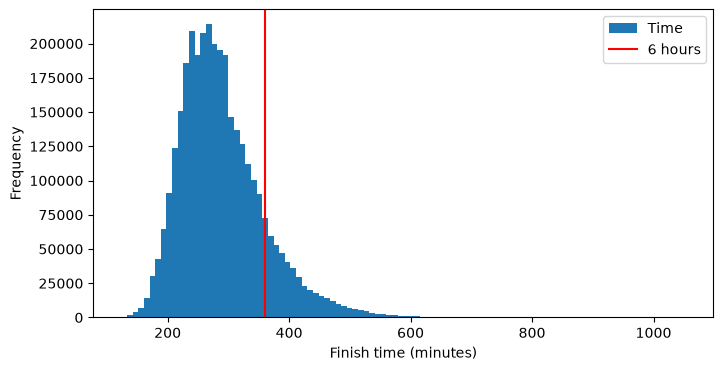

In [31]:
ax = df["Time"].plot.hist(bins=100, figsize=(8, 4))
ax.axvline(360, color="red", label="6 hours")
ax.set_xlabel("Finish time (minutes)")
ax.legend();

## Finish time by race

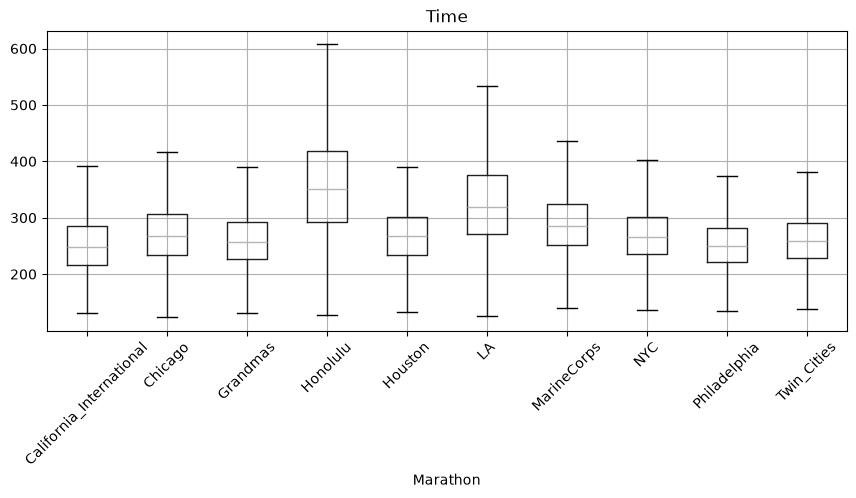

In [32]:
df.boxplot(column="Time", by="Marathon", showfliers=False, figsize=(10, 4), rot=45)
plt.suptitle("");

## Share of runners slower than 6h

In [33]:
df["Slow"] = df["Time"] > 360  # finished in over 6 hours
df.groupby("Marathon")["Slow"].agg(["size", "mean"]).sort_values("mean").round(3)

,size,mean
Marathon,,
Houston,120095,0.007
Twin_Cities,139312,0.008
Philadelphia,155075,0.029
California_International,98829,0.029
Grandmas,121776,0.036
NYC,800678,0.064
Chicago,714761,0.067
MarineCorps,388744,0.105
LA,376503,0.310


<Axes: xlabel='Year', ylabel='Share > 6h'>

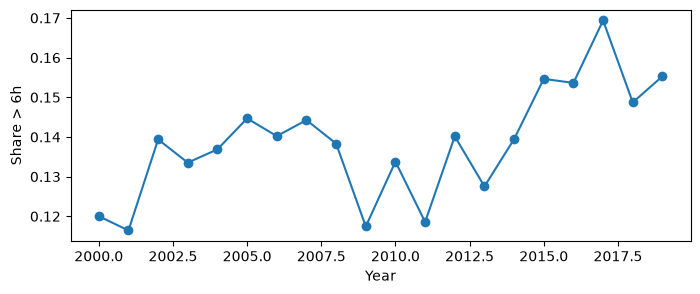

In [34]:
df.groupby("Year")["Slow"].mean().plot(marker="o", figsize=(8, 3), ylabel="Share > 6h")

## Sex and age

In [35]:
df.groupby("Sex")["Slow"].agg(["size", "mean"]).round(3)

,size,mean
Sex,,
F,1379403,0.193
M,1963813,0.102


<Axes: xlabel='Age', ylabel='Frequency'>

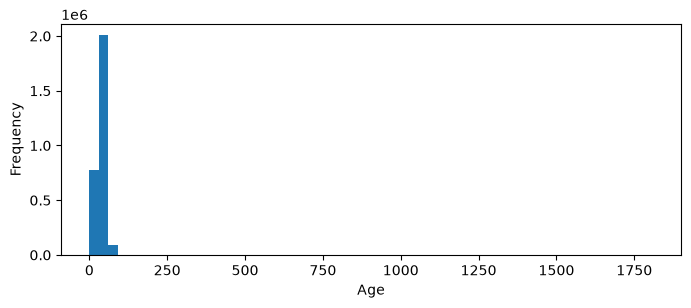

In [36]:
df["Age"].plot.hist(bins=60, figsize=(8, 3), xlabel="Age")

<Axes: xlabel='Age', ylabel='Median time (minutes)'>

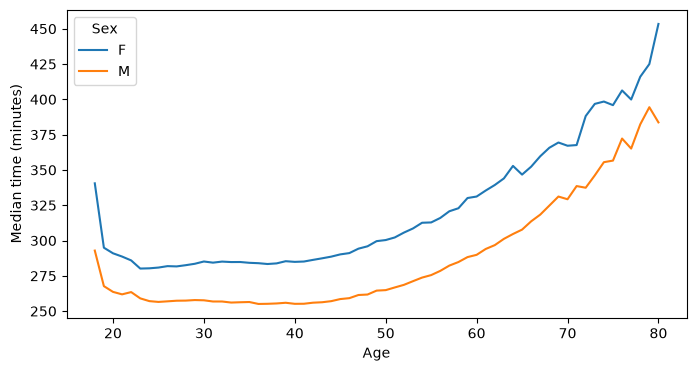

In [37]:
df[df["Age"].between(18, 80)].groupby(["Age", "Sex"])["Time"].median().unstack().plot(
    figsize=(8, 4), ylabel="Median time (minutes)")

## Messy columns

In [38]:
df["Sex1"].value_counts(dropna=False).head(15)

Sex1
M              1866575
F              1319198
NaN             152445
MOpen             2171
FOpen             1674
MElite             191
MClydesdale        158
FElite             153
Melite              75
Mclydesdale         74
Felite              72
FAthena             58
MElites             55
FElites             43
MM-15               36
Name: count, dtype: int64

In [39]:
df["Agegroup"].value_counts(dropna=False)

Agegroup
18-34    1259376
35-39     519653
40-44     501278
45-49     388275
50-54     291303
55-59     166426
60-64      95513
17U        47034
65-69      39445
70-74      14768
15-19       7284
75-79       4055
NaN         3096
0-19        1675
16-19       1546
80+         1513
0-14         382
14-19        160
10-21        128
0-21         106
12-18         86
5-9           38
70-99         20
0-17          19
0-15          15
12-15          9
43814          6
10-14          3
0-9            2
0-10           1
0-4            1
Name: count, dtype: int64

In [40]:
df[["Country", "data"]].sample(10, random_state=0)

,Country,data
43181,"Edina,","MN, USA 3:33:50"
1636465,"NC,",USA
2618329,DIAMOND,"BAR, CA, USA 4:37:50"
195383,4:24:54,
1541538,"VA,",USA
402009,"Vienna,","VA, USA"
1256240,NaN,"San Jose, CA, USA"
2955092,NaN,ITA 4:21:37
1448621,NaN,"Sping Valley, CA, USA 4:00:54"
2248612,NaN,"Christiansted, VI, USA 6:23:07"


## Columns that leak the target

In [41]:
leak = df[["Time"]].copy()
leak["Gun Time"] = pd.to_timedelta(df["Gun Time"], errors="coerce").dt.total_seconds() / 60
leak["Place"] = pd.to_numeric(df["Place"], errors="coerce")
leak.corr().round(3)

,Time,Gun Time,Place
Time,1.000,0.995,0.515
Gun Time,0.995,1.000,0.673
Place,0.515,0.673,1.000


## Correlation matrix

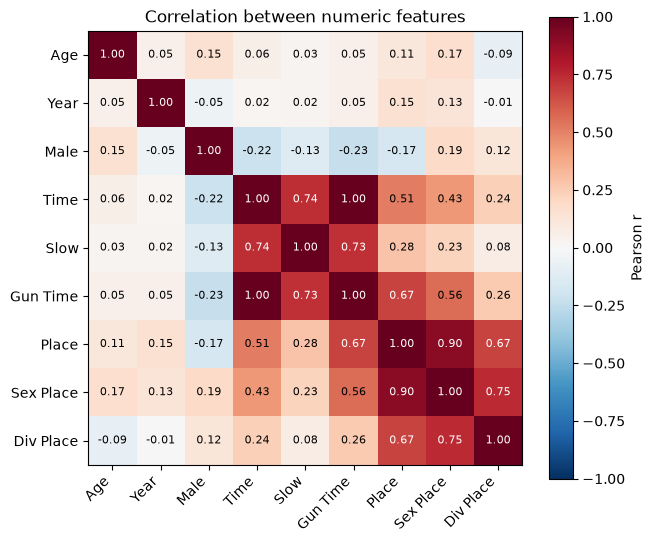

In [42]:
num = pd.DataFrame({
    "Age": df["Age"],
    "Year": df["Year"],
    "Male": (df["Sex"] == "M").astype(float),
    "Time": df["Time"],
    "Slow": (df["Time"] > 360).astype(float),
    "Gun Time": pd.to_timedelta(df["Gun Time"], errors="coerce").dt.total_seconds() / 60,
    "Place": pd.to_numeric(df["Place"], errors="coerce"),
    "Sex Place": pd.to_numeric(df["Sex Place"], errors="coerce"),
    "Div Place": df["Div Place"],
})
corr = num.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Correlation between numeric features");

## Repeat runners

In [43]:
key = df["Name"].str.upper().str.strip() + "|" + df["Sex"] + "|" + (df["Year"] - df["Age"]).astype("Int64").astype(str)
races_per_runner = key[df["Age"].notna()].value_counts()
races_per_runner.value_counts().sort_index().head(10)

count
1     1320120
2      277089
3      102089
4       47863
5       25958
6       14916
7        9033
8        5716
9        3962
10       2789
Name: count, dtype: int64

## Marine Corps only

In [44]:
mcm = df[df["Marathon"] == "MarineCorps"]
mcm.groupby("Year").agg(runners=("Time", "size"), slow_share=("Slow", "mean")).round(3)

,runners,slow_share
Year,,
2000,17001,0.087
2001,14206,0.061
2002,14076,0.071
2003,15948,0.085
2004,16292,0.115
2005,19100,0.107
2006,20856,0.080
2007,20622,0.077
2008,18219,0.072
